<a href="https://colab.research.google.com/github/AnanyaKasiraj2529/Data-Analytics-and-AI-ML--Learning-additional-/blob/main/Pokemon_fastai_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pokémon Image Classifier with fast.ai



**Goal:** Train a model to recognise 10 Pokémon species from images, then test it on an image it has not seen during training.

We will use **transfer learning**: start with a model that already knows general visual patterns, then fine-tune it on Pokémon images.




## 1. Install the libraries

- `fastai` gives us convenient tools for image classification and training.
- `datasets` downloads the labelled Pokémon dataset from Hugging Face.
- `Pillow` handles image files.


In [ ]:
!pip -q install fastai datasets

## 2. Import the tools

`vision.all` gives us the main fast.ai computer-vision tools in one import.


In [ ]:
from fastai.vision.all import *
from datasets import load_dataset
from pathlib import Path
from PIL import Image
from io import BytesIO
from collections import Counter
import os, re

print("fast.ai is ready!")

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


fast.ai is ready!


## 3. Choose 10 Pokémon and load labelled images

We use the Hugging Face dataset **JJMack/pokemon-classification-gen1-9**. It contains Pokémon images and metadata, including each Pokémon's name.

To keep the classroom demo small, we collect up to **30 images per Pokémon** for these ten species. The dataset is streamed so we do not intentionally download the entire collection into memory.

If one of the selected names is missing or has too few images, check the counts printed below and replace it with a Pokémon that appears in the dataset.


In [ ]:
# Ten classes for our small demonstration
pokemon_names = [
    "Bulbasaur", "Charmander", "Squirtle", "Pikachu", "Eevee",
    "Meowth", "Psyduck", "Jigglypuff", "Snorlax", "Mewtwo"
]

IMAGES_PER_CLASS = 30
data_dir = Path("/content/pokemon_demo")
data_dir.mkdir(parents=True, exist_ok=True)

# Create one folder per Pokémon. fast.ai will use folder names as labels.
for name in pokemon_names:
    (data_dir / name).mkdir(exist_ok=True)

# Stream the dataset and save only the selected Pokémon.
dataset = load_dataset(
    "JJMack/pokemon-classification-gen1-9",
    split="train",
    streaming=True
)

saved_counts = Counter()
primary_type_by_name = {}

def safe_image(value):
    """Convert a Hugging Face image value into a PIL image."""
    if isinstance(value, Image.Image):
        return value
    if isinstance(value, dict):
        if value.get("bytes"):
            return Image.open(BytesIO(value["bytes"]))
        if value.get("path"):
            return Image.open(value["path"])
    return None

for row in dataset:
    # The dataset card identifies these fields as name and image_data.
    raw_name = str(row.get("name", "")).strip().casefold()
    matching_name = next(
        (p for p in pokemon_names if p.casefold() == raw_name),
        None
    )

    if matching_name is None or saved_counts[matching_name] >= IMAGES_PER_CLASS:
        continue

    image = safe_image(row.get("image_data"))
    if image is None:
        continue

    try:
        image = image.convert("RGB")
        filename = data_dir / matching_name / f"{matching_name}_{saved_counts[matching_name]:03d}.jpg"
        image.save(filename, quality=95)
        saved_counts[matching_name] += 1
        primary_type_by_name[matching_name] = row.get('Type 1', 'Unknown')
    except Exception:
        pass

    if all(saved_counts[p] >= IMAGES_PER_CLASS for p in pokemon_names):
        break

print("Images collected:")
for name in pokemon_names:
    print(f"{name}: {saved_counts[name]}")

missing = [name for name in pokemon_names if saved_counts[name] < 8]
if missing:
    print("\nSome classes have fewer than 8 images:", missing)
    print("Replace these names with classes that have more images, then rerun this cell.")
else:
    print("\nPrimary elemental types:")
    for name in pokemon_names:
        print(name, ":", primary_type_by_name.get(name, "Unknown"))
    print("\nGreat! We have enough images to continue.")

README.md:   0%|          | 0.00/28.4k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Images collected:
Bulbasaur: 30
Charmander: 30
Squirtle: 30
Pikachu: 27
Eevee: 30
Meowth: 30
Psyduck: 28
Jigglypuff: 28
Snorlax: 30
Mewtwo: 27

Primary elemental types:
Bulbasaur : Grass
Charmander : Fire
Squirtle : Water
Pikachu : Electric
Eevee : Normal
Meowth : Normal
Psyduck : Water
Jigglypuff : Normal
Snorlax : Normal
Mewtwo : Psychic

Great! We have enough images to continue.


## 4. Look at our dataset

Before training, let's inspect a few images. This helps us check that the labels and images make sense.

**Explain in class:** Each image is an example, and its folder name is the correct answer (label).


In [ ]:
get_image_files(data_dir)[:5], len(get_image_files(data_dir))

([Path('/content/pokemon_demo/Meowth/Meowth_013.jpg'), Path('/content/pokemon_demo/Meowth/Meowth_001.jpg'), Path('/content/pokemon_demo/Meowth/Meowth_017.jpg'), Path('/content/pokemon_demo/Meowth/Meowth_023.jpg'), Path('/content/pokemon_demo/Meowth/Meowth_025.jpg')],
 290)

Example label: Meowth
Bulbasaur -> 30 images
Charmander -> 30 images
Squirtle -> 30 images
Pikachu -> 27 images
Eevee -> 30 images
Meowth -> 30 images
Psyduck -> 28 images
Jigglypuff -> 28 images
Snorlax -> 30 images
Mewtwo -> 27 images


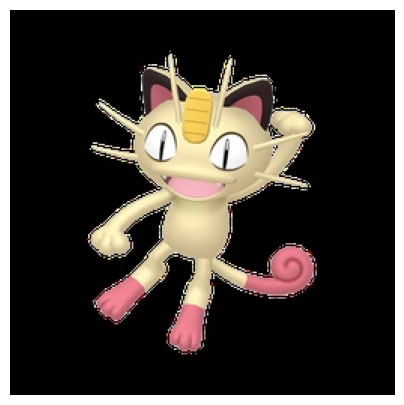

In [ ]:
# Display a few examples from the folders
files = get_image_files(data_dir)
if files:
    show_image(Image.open(files[0]))
    print("Example label:", files[0].parent.name)

# Show a grid of images from our selected classes
for name in pokemon_names:
    class_files = get_image_files(data_dir / name)
    if class_files:
        print(name, "->", len(class_files), "images")

## 5. Prepare training and validation data

A model needs examples to learn from and separate examples to check how well it is doing.

- **Training set:** images the model learns from.
- **Validation set:** images held back while training, used to check performance on examples it did not train on.

We use an 80/20 split.


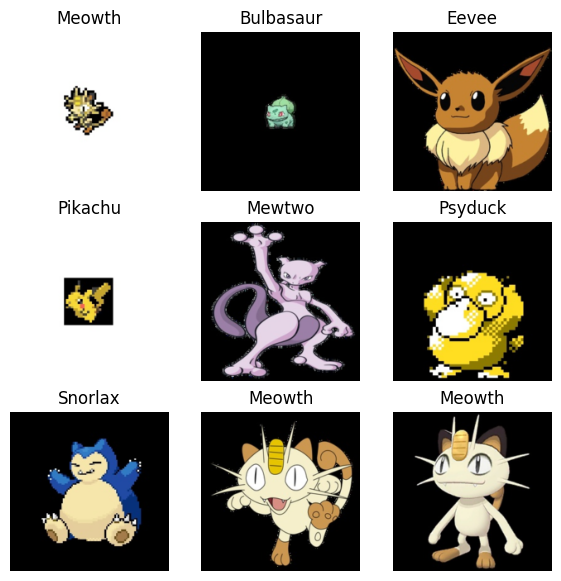

In [ ]:
dls = ImageDataLoaders.from_folder(
    data_dir,
    valid_pct=0.2,
    seed=42,
    item_tfms=Resize(192),
    bs=32
)

dls.show_batch(max_n=9, figsize=(7, 7))

## 6. Create the model with ResNet18

`ResNet18` is a convolutional neural network (CNN), a type of model commonly used for image recognition.

`vision_learner` connects the model to our data. We use pretrained weights, so it starts with visual knowledge learned from a large image dataset.

`accuracy` tells us the proportion of validation predictions that are correct.


In [ ]:
learn = vision_learner(
    dls,
    resnet18,
    metrics=accuracy
)

print("Model created!")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 182MB/s]


Model created!


## 7. Train it: fine-tuning

`fine_tune(3)` asks fast.ai to adapt the pretrained model to our Pokémon images over three epochs.

An **epoch** is one pass through the training data.

We keep the number of epochs small so the classroom demonstration stays manageable. Training time depends on the runtime and available GPU.


In [ ]:
learn.fine_tune(3)

epoch,train_loss,valid_loss,accuracy,time
0,3.224436,1.865468,0.413793,00:31


epoch,train_loss,valid_loss,accuracy,time
0,1.477499,0.997563,0.706897,00:43
1,0.917512,0.730671,0.810345,00:44
2,0.651653,0.657206,0.827586,00:43


## 8. Check the result

Let's inspect the validation accuracy and a few predictions.

Accuracy is useful, but it is not the whole story: a small dataset can make the score unstable, and similar-looking images can still confuse the model.


In [ ]:
validation_accuracy = learn.validate()[1]
print(f"Validation accuracy: {validation_accuracy:.1%}")

Validation accuracy: 82.8%


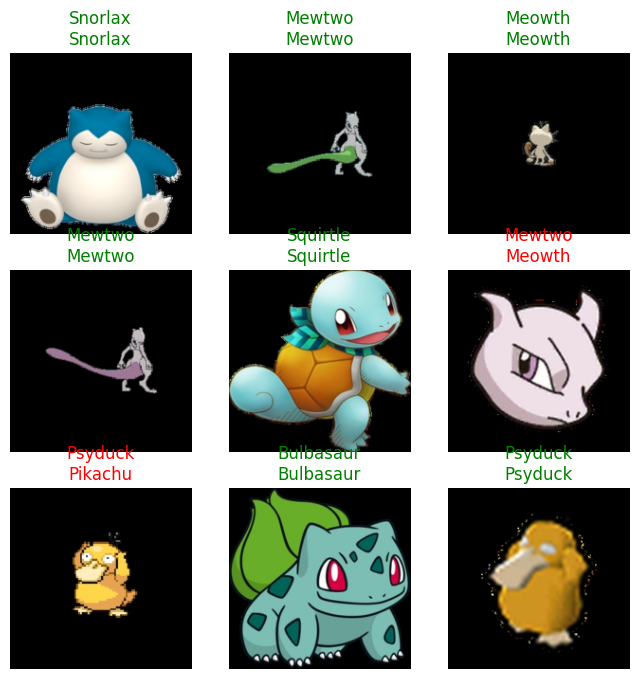

In [ ]:
learn.show_results(max_n=9, figsize=(8, 8))

## 9. Try a prediction on an unseen image

This takes an image from the validation set, which was held out from training, and asks the model to predict its Pokémon label.

The output includes:
1. the predicted class,
2. the model's confidence for that class,
3. the scores for all classes.


In [ ]:
# Pick one image from the validation set
test_image = dls.valid.items[0]

predicted_label, predicted_index, probabilities = learn.predict(test_image)

print("Image:", test_image)
print("Predicted Pokémon:", predicted_label)
print("Primary elemental type:", primary_type_by_name.get(str(predicted_label), "Unknown"))
print("Confidence:", f"{probabilities[predicted_index]:.1%}")

Image: /content/pokemon_demo/Meowth/Meowth_017.jpg
Predicted Pokémon: Meowth
Primary elemental type: Normal
Confidence: 97.2%


In [ ]:
# Optional: upload a different Pokémon image and ask the model to classify it.
# In Colab, choose an image file when prompted.
from google.colab import files

uploaded = files.upload()

for filename in uploaded:
    prediction, pred_idx, probs = learn.predict(filename)
    print("Predicted Pokémon:", prediction)
    print("Primary elemental type:", primary_type_by_name.get(str(prediction), "Unknown"))
    print("Confidence:", f"{probs[pred_idx]:.1%}")

Saving bulbasaur.jpeg to bulbasaur.jpeg


Predicted Pokémon: Meowth
Primary elemental type: Normal
Confidence: 65.3%


## 10. What did we learn?

- We used labelled images to teach a computer to recognise 10 Pokémon.
- fast.ai organised the images into training and validation data.
- ResNet18 provided a pretrained starting point.
- Fine-tuning adapted that model to our Pokémon classes.
- We tested it on images that were held out from training.

### Limitations
- This is a small demonstration dataset, not a production-ready Pokédex.
- Some Pokémon may have fewer or more varied images than others.
- The model may perform poorly on toys, screenshots, unusual poses, or images with different backgrounds.
- Validation accuracy is not proof that the model will work equally well on every real-world image.

**Next idea:** Once species recognition works, we can add a small lookup table to display the Pokémon's elemental type after the model predicts its name.
